# Análise exploratória — Heart Failure Prediction Dataset

Trabalho final de Aprendizado de Máquina (DEIN0118, UFMA, 2026.2).

Este notebook segue o roteiro de perguntas do material de estudos de AED: para cada pergunta há
uma célula de código que a responde e uma frase de conclusão. As figuras do artigo são geradas
pelas mesmas funções, em `src/eda.py`.

**Regra de leitura dos dados.** Estrutura e qualidade são examinadas no conjunto completo.
As relações entre atributos e alvo são examinadas apenas no conjunto de treino, para que nenhuma
decisão de modelagem dependa do conjunto de teste.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src import config, eda, plotting
from src.data import load_data, split_data

plotting.apply_style()
pd.set_option("display.width", 160)

df = load_data()
X_train, X_test, y_train, y_test = split_data(df)
train = X_train.assign(**{config.TARGET: y_train})
print(f"completo: {df.shape} | treino: {X_train.shape} | teste: {X_test.shape} | semente: {config.SEED}")

completo: (918, 12) | treino: (734, 11) | teste: (184, 11) | semente: 42


## 1. Estrutura — quantas linhas e colunas? O que é cada linha?

In [2]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
print(df.shape)

(918, 12)


**Conclusão.** São 918 linhas e 12 colunas. Cada linha é um paciente; 11 colunas são atributos
clínicos e `HeartDisease` é o alvo. O volume supera o mínimo de 500 instâncias e permite separar
734 pacientes para treino e 184 para teste.

## 2. Tipos — o tipo lido bate com o significado?

In [4]:
eda.data_dictionary(df)

,coluna,descricao,tipo,valores,pct_ausente_explicito,observacao
0,Age,Idade,numérica,28 a 77 anos,0.0,
1,Sex,Sexo,categórica nominal,"M (Masculino), F (Feminino)",0.0,
2,ChestPainType,Tipo de dor no peito,categórica nominal,"ASY (Assintomático), ATA (Angina atípica), NAP...",0.0,
3,RestingBP,Pressão arterial em repouso,numérica,0 a 200 mm Hg,0.0,1 zeros = não medido (0.1%)
4,Cholesterol,Colesterol sérico,numérica,0 a 603 mg/dl,0.0,172 zeros = não medido (18.7%)
5,FastingBS,Glicemia de jejum > 120 mg/dl,binária,"0, 1",0.0,
6,RestingECG,ECG em repouso,categórica nominal,"Normal (Normal), ST (Anormalidade de onda ST-T...",0.0,
7,MaxHR,Frequência cardíaca máxima,numérica,60 a 202 bpm,0.0,
8,ExerciseAngina,Angina induzida por exercício,categórica nominal,"N (Não), Y (Sim)",0.0,
9,Oldpeak,Depressão de ST (oldpeak),numérica,-2.6 a 6.2 mm,0.0,


**Conclusão.** Cinco atributos são numéricos (`Age`, `RestingBP`, `Cholesterol`, `MaxHR`,
`Oldpeak`), cinco são categóricos nominais lidos como texto (`Sex`, `ChestPainType`,
`RestingECG`, `ExerciseAngina`, `ST_Slope`) e `FastingBS` é binário, já codificado como 0/1:
apesar de ser lido como inteiro, não é uma quantidade. Não há identificadores nem datas.

## 3. Qualidade — há ausentes, duplicados ou valores impossíveis?

In [5]:
print("ausentes explícitos:", int(df.isna().sum().sum()))
print("linhas duplicadas:  ", int(df.duplicated().sum()))
df[config.NUMERIC_ALL].describe().T.round(2)

ausentes explícitos: 0
linhas duplicadas:   0


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.51,9.43,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.40,18.51,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.80,109.38,0.0,173.25,223.0,267.0,603.0
MaxHR,918.0,136.81,25.46,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.89,1.07,-2.6,0.00,0.6,1.5,6.2


In [6]:
zeros = {c: int((df[c] == 0).sum()) for c in config.NUM_ZERO_AS_MISSING}
print("zeros fisiologicamente impossíveis:", zeros)
print(f"colesterol = 0 em {zeros['Cholesterol'] / len(df):.1%} dos registros")
print("oldpeak negativo:", int((df['Oldpeak'] < 0).sum()), "registros")

zeros fisiologicamente impossíveis: {'RestingBP': 1, 'Cholesterol': 172}
colesterol = 0 em 18.7% dos registros
oldpeak negativo: 13 registros


**Conclusão.** Não há valores ausentes explícitos nem linhas duplicadas, mas o `describe()` mostra
mínimo 0 em `RestingBP` e `Cholesterol`. Zero é impossível para as duas medidas: é um código de
"não medido" disfarçado, presente em 172 registros de colesterol (18,7%) e em 1 de pressão.
Decisão: tratar o zero como ausente e imputar a mediana do treino dentro do pipeline.
`Oldpeak` negativo (13 registros) é plausível (elevação de ST) e foi mantido.

### O colesterol ausente é ao acaso?

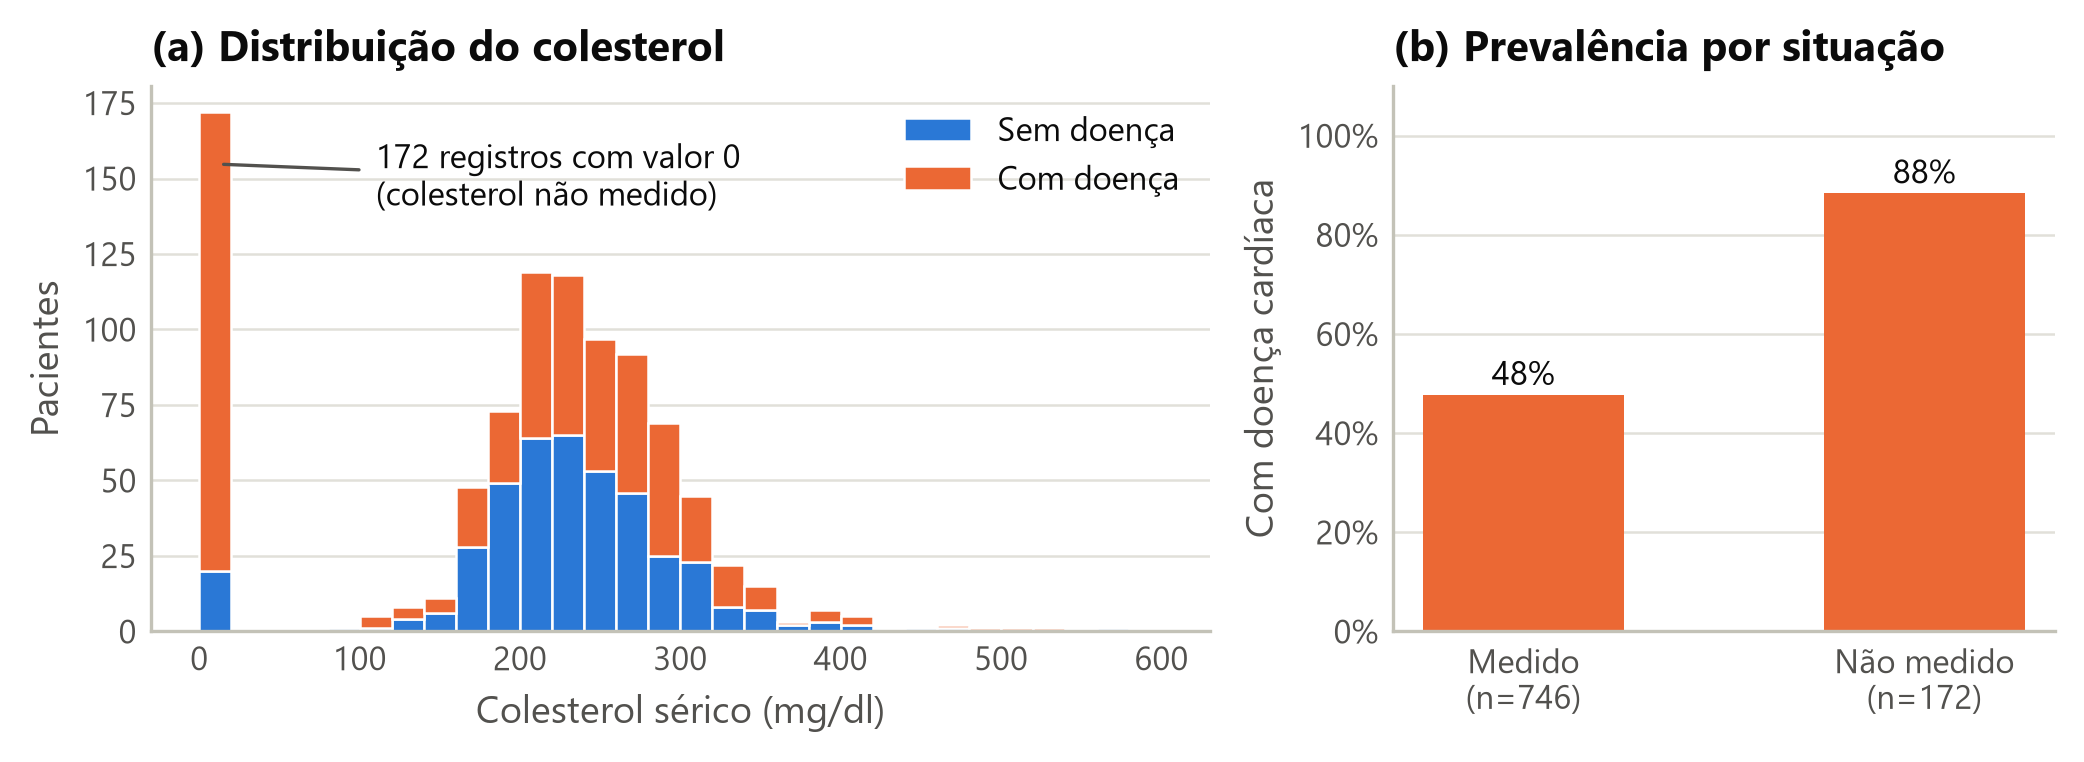

,count,mean
colesterol_medido,,
False,172,0.884
True,746,0.477


In [7]:
eda.fig_cholesterol_zero(df)
display(Image(str(config.FIGURES_DIR / "fig05_colesterol_ausente.png"), width=760))
df.assign(colesterol_medido=df["Cholesterol"] > 0).groupby("colesterol_medido")[config.TARGET].agg(["count", "mean"]).round(3)

**Conclusão.** Não. Entre os pacientes sem colesterol medido, 88% têm doença cardíaca; entre os
demais, 48%. A ausência depende do alvo e, provavelmente, da base de origem do registro. Um
indicador de "colesterol ausente" melhoraria as métricas neste conjunto, mas ensinaria ao modelo
um artefato de coleta, não um sinal clínico. Decisão: imputar a mediana **sem** criar a coluna
indicadora, e medir o efeito dessa escolha em um experimento de sensibilidade.

### Outliers

In [8]:
pd.Series({c: eda.iqr_outliers(df[c]) for c in config.NUMERIC_ALL}, name="outliers (critério IQR)").to_frame().assign(
    sem_zeros=lambda t: [eda.iqr_outliers(df.loc[df[c] > 0, c]) if c in config.NUM_ZERO_AS_MISSING else np.nan for c in t.index]
)

,outliers (critério IQR),sem_zeros
Age,0,NaN
RestingBP,28,27.0
Cholesterol,183,23.0
MaxHR,2,NaN
Oldpeak,16,NaN


**Conclusão.** Pelo critério do IQR, `Cholesterol` tem 183 valores suspeitos, mas 172 deles são os
zeros já discutidos; sem os zeros restam 23 valores, quase todos altos e clinicamente possíveis.
`RestingBP` tem 28 e `Oldpeak` 16, também plausíveis. Decisão: não remover outliers; a padronização
atende os modelos sensíveis à escala e os ensembles de árvores são robustos a eles.

## 4. Alvo — as classes estão balanceadas?

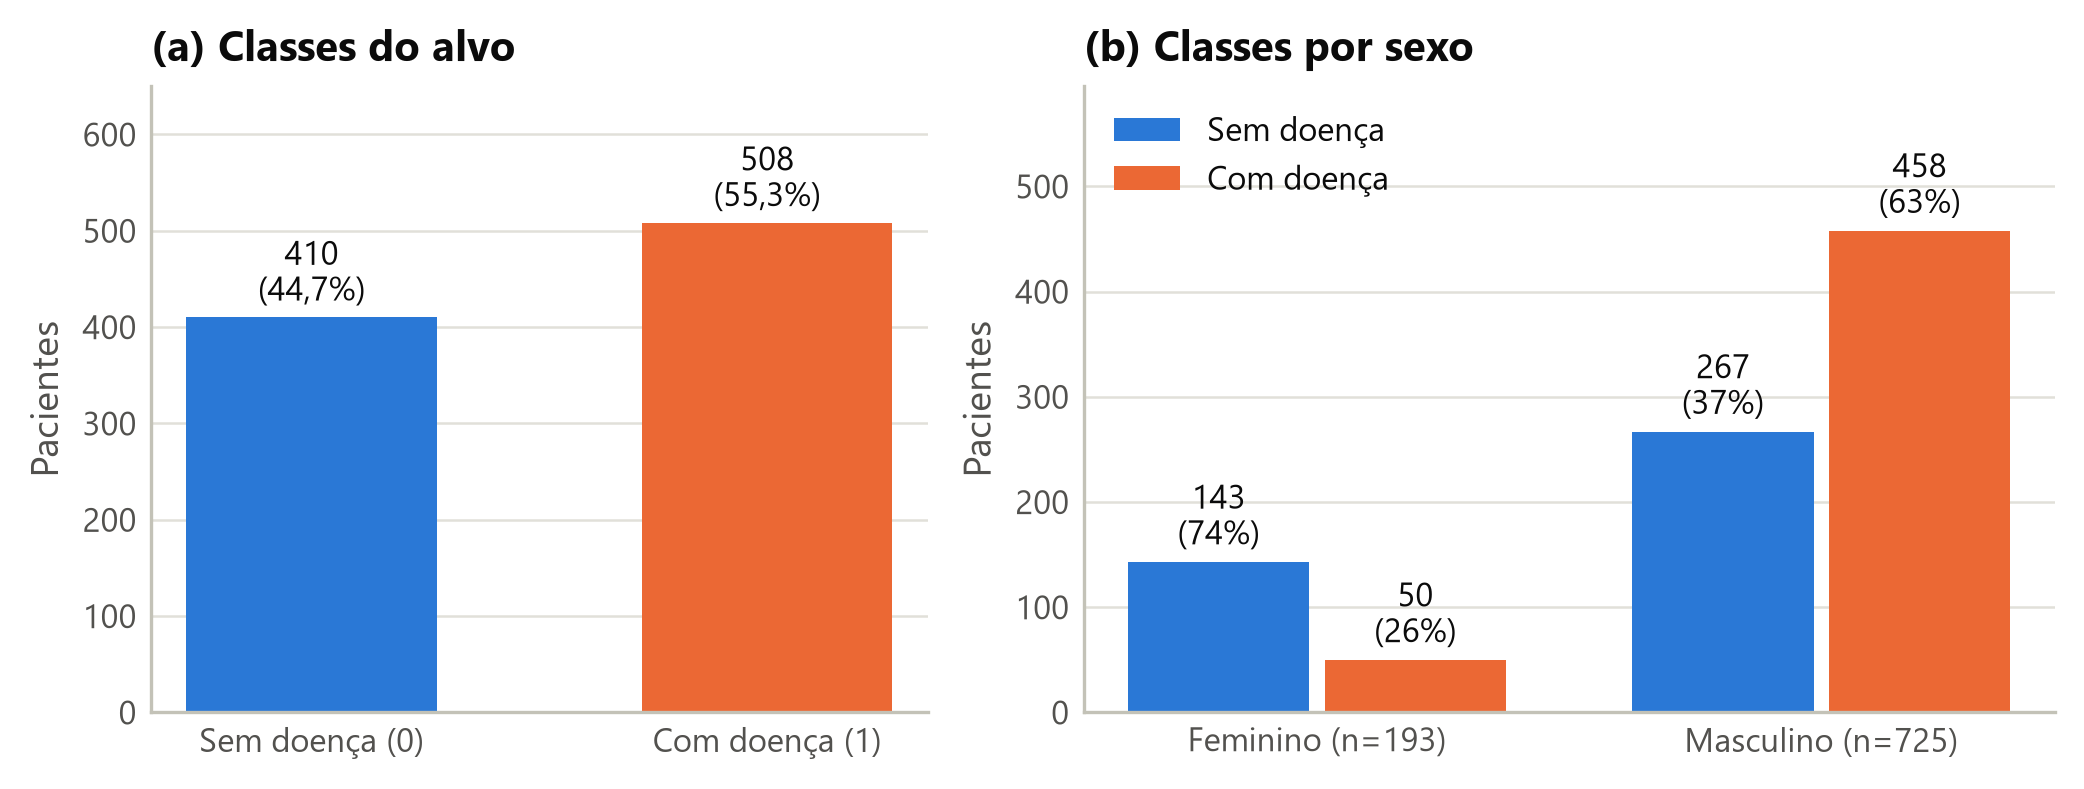

HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64

In [9]:
eda.fig_target(df)
display(Image(str(config.FIGURES_DIR / "fig01_distribuicao_alvo.png"), width=760))
df[config.TARGET].value_counts(normalize=True).round(3)

**Conclusão.** 55,3% dos pacientes têm doença cardíaca e 44,7% não: o desbalanceamento é leve e não
exige reamostragem. Decisão: usar divisão e validação cruzada estratificadas e testar
`class_weight="balanced"` na busca de hiperparâmetros. Já a distribuição por sexo é muito desigual:
79% dos registros são de homens, e só 50 mulheres têm o desfecho positivo. Isso limita o que se
pode afirmar sobre o desempenho em mulheres.

## 5. Atributos — como se distribuem por classe? (treino)

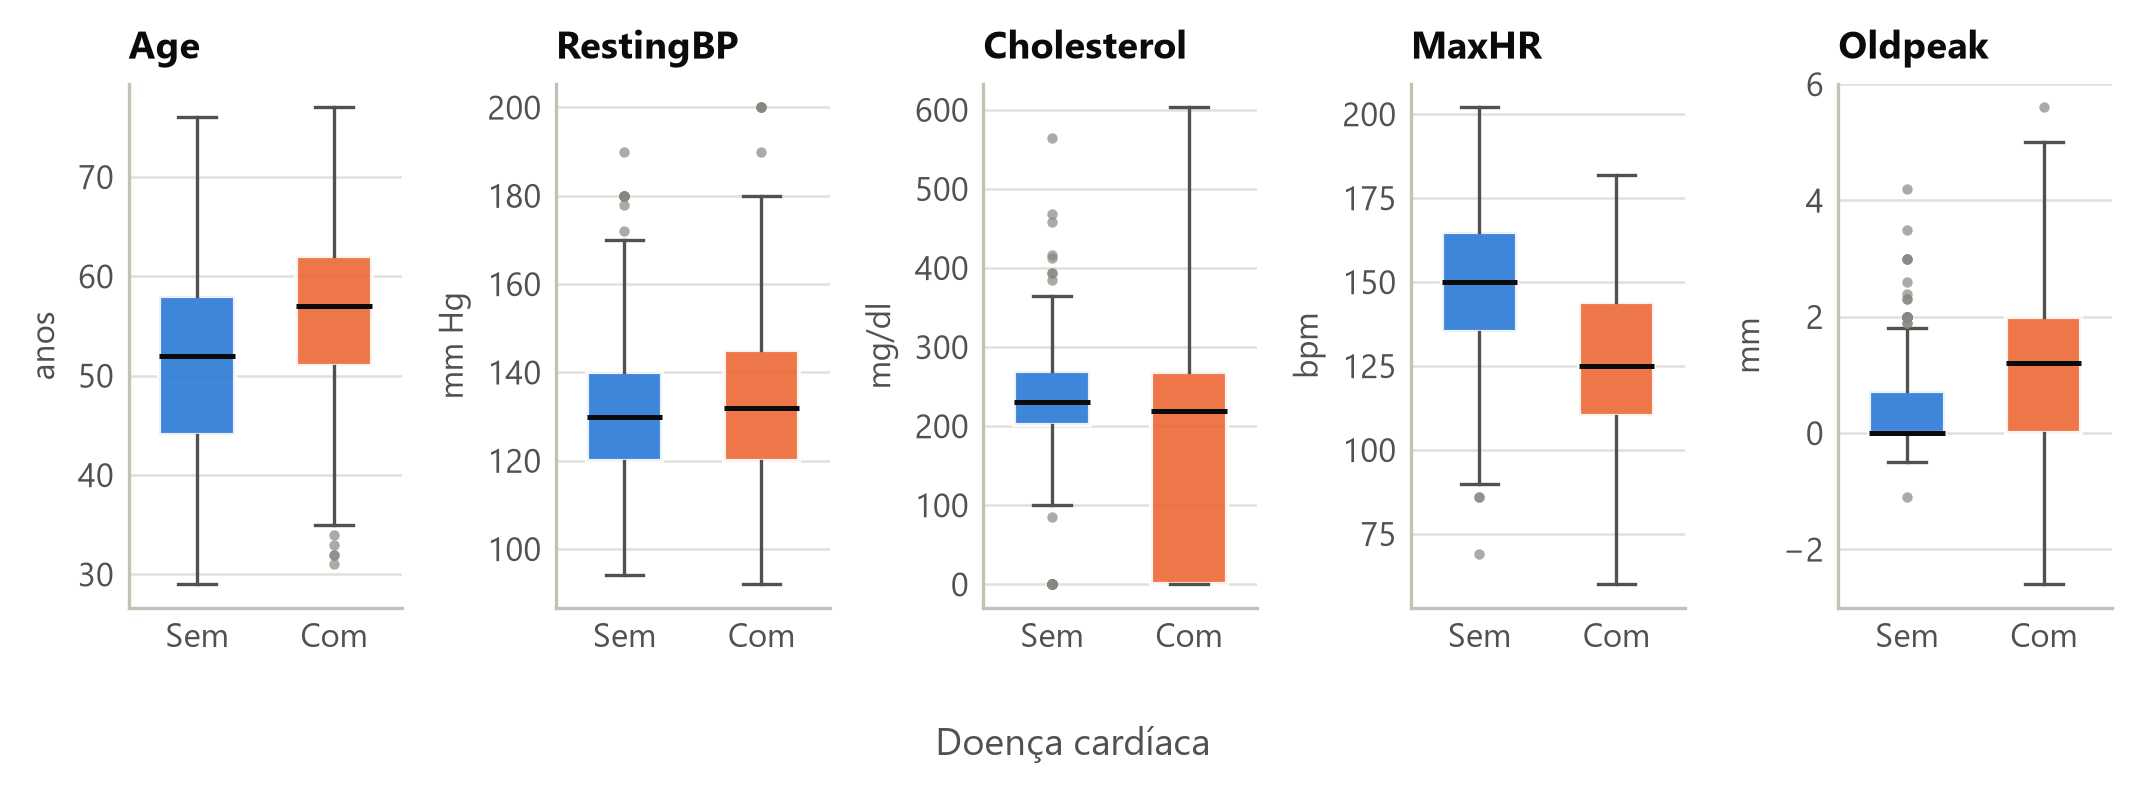

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
HeartDisease,,,,,
0,52.0,130.0,230.0,150.0,0.0
1,57.0,132.0,219.0,125.0,1.2


In [10]:
eda.fig_numeric_by_class(train)
display(Image(str(config.FIGURES_DIR / "fig02_numericas_por_classe.png"), width=820))
train.groupby(config.TARGET)[config.NUMERIC_ALL].median()

**Conclusão.** Pacientes com doença são mais velhos (mediana 57 contra 52 anos), atingem frequência
cardíaca máxima menor (125 contra 150 bpm) e têm `Oldpeak` maior. `RestingBP` quase não separa as
classes. As escalas são muito diferentes entre atributos, o que justifica a padronização.

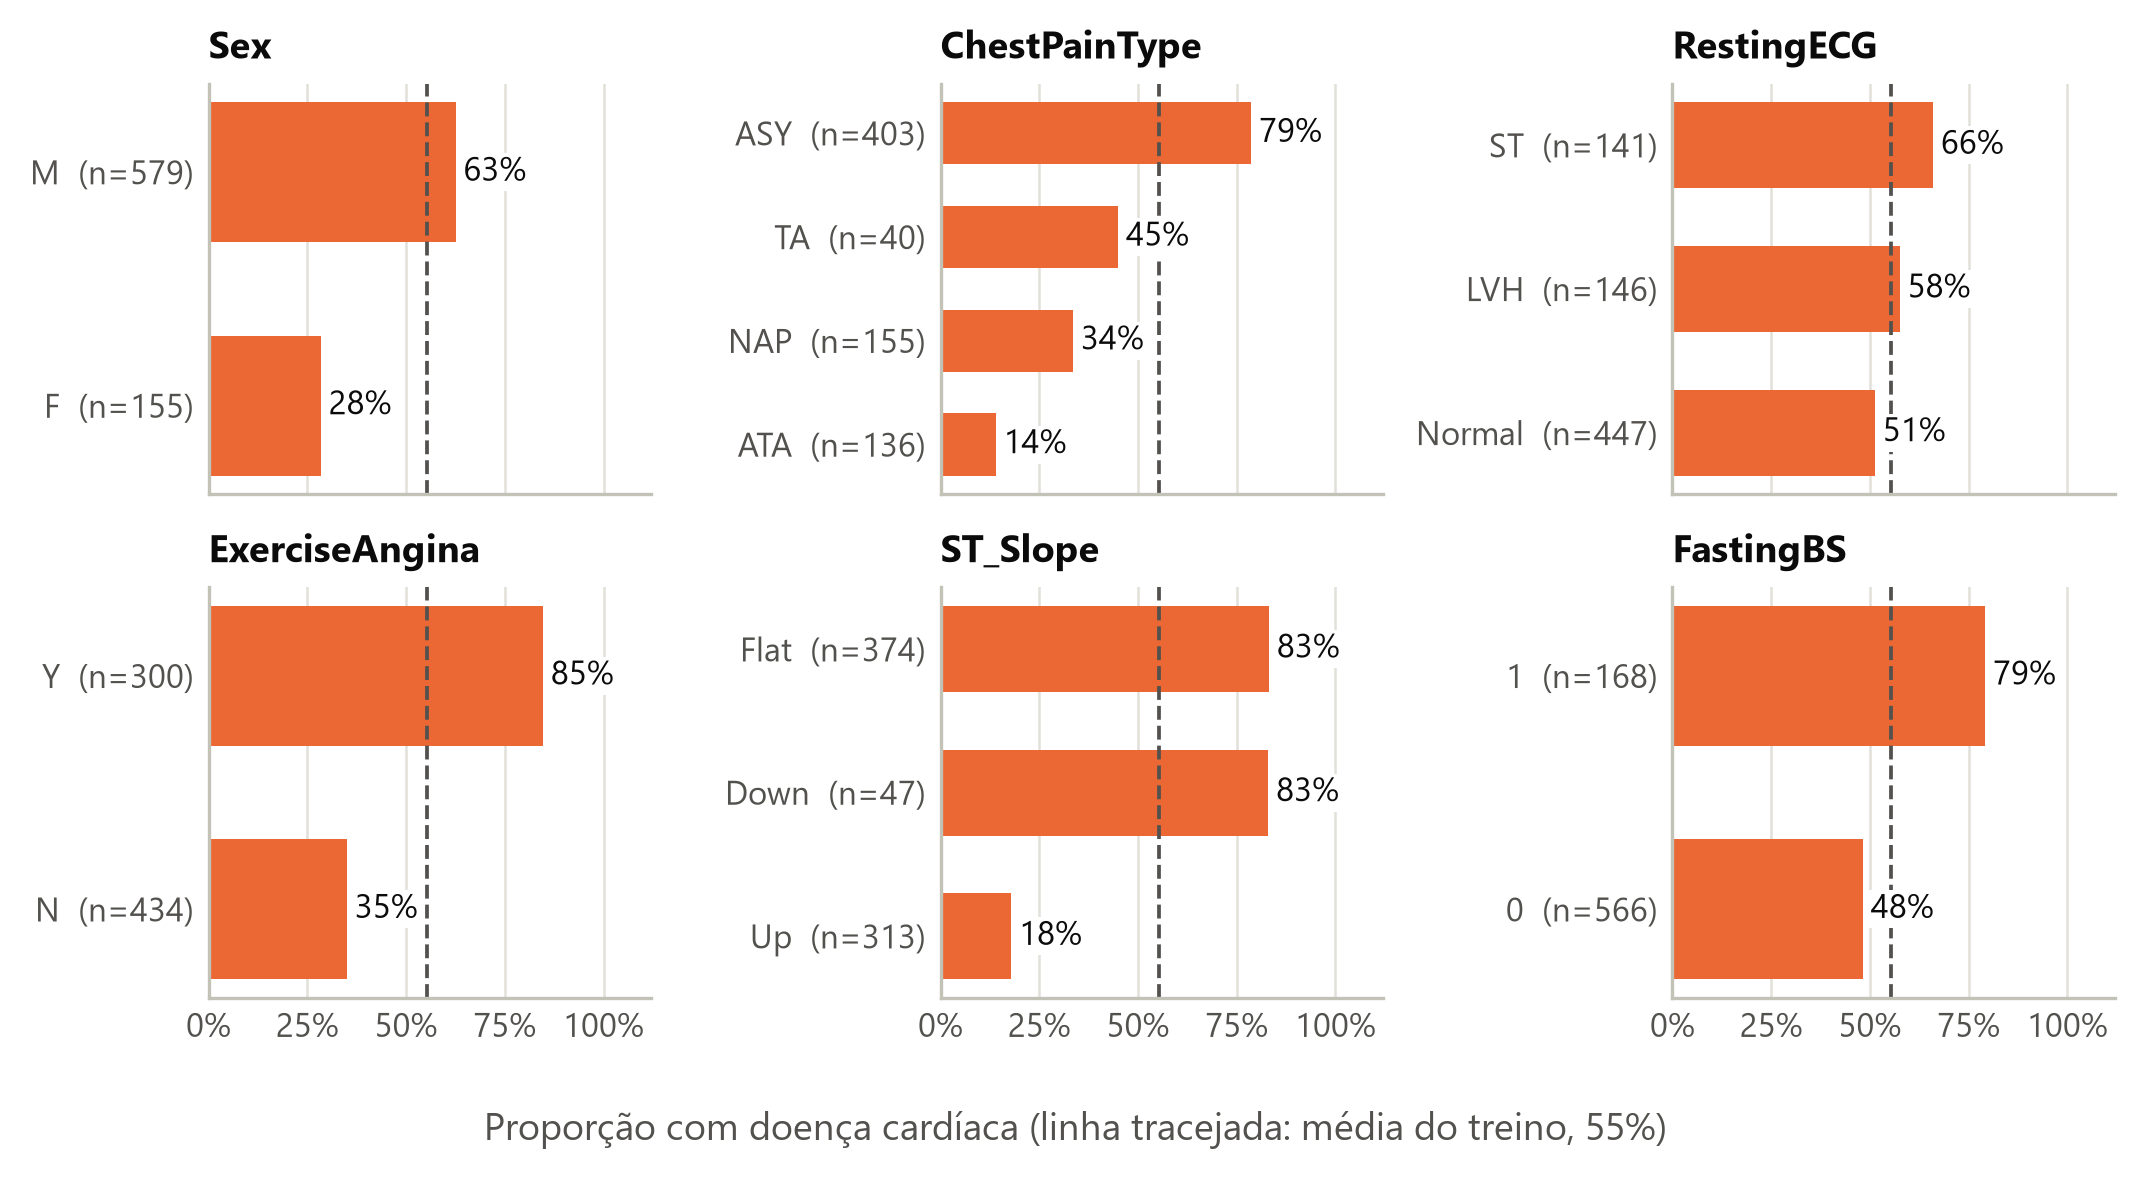

In [11]:
eda.fig_categorical_prevalence(train)
display(Image(str(config.FIGURES_DIR / "fig03_categoricas_por_classe.png"), width=820))

**Conclusão.** Os atributos categóricos separam as classes melhor do que os numéricos: a doença
aparece em 83% dos pacientes com `ST_Slope` plano contra 18% com inclinação ascendente; em 85% dos
que têm angina no esforço contra 35% dos que não têm; e em 79% dos assintomáticos (`ASY`) contra
14% dos que têm angina atípica (`ATA`).

## 6. Relações — os atributos são redundantes entre si? (treino)

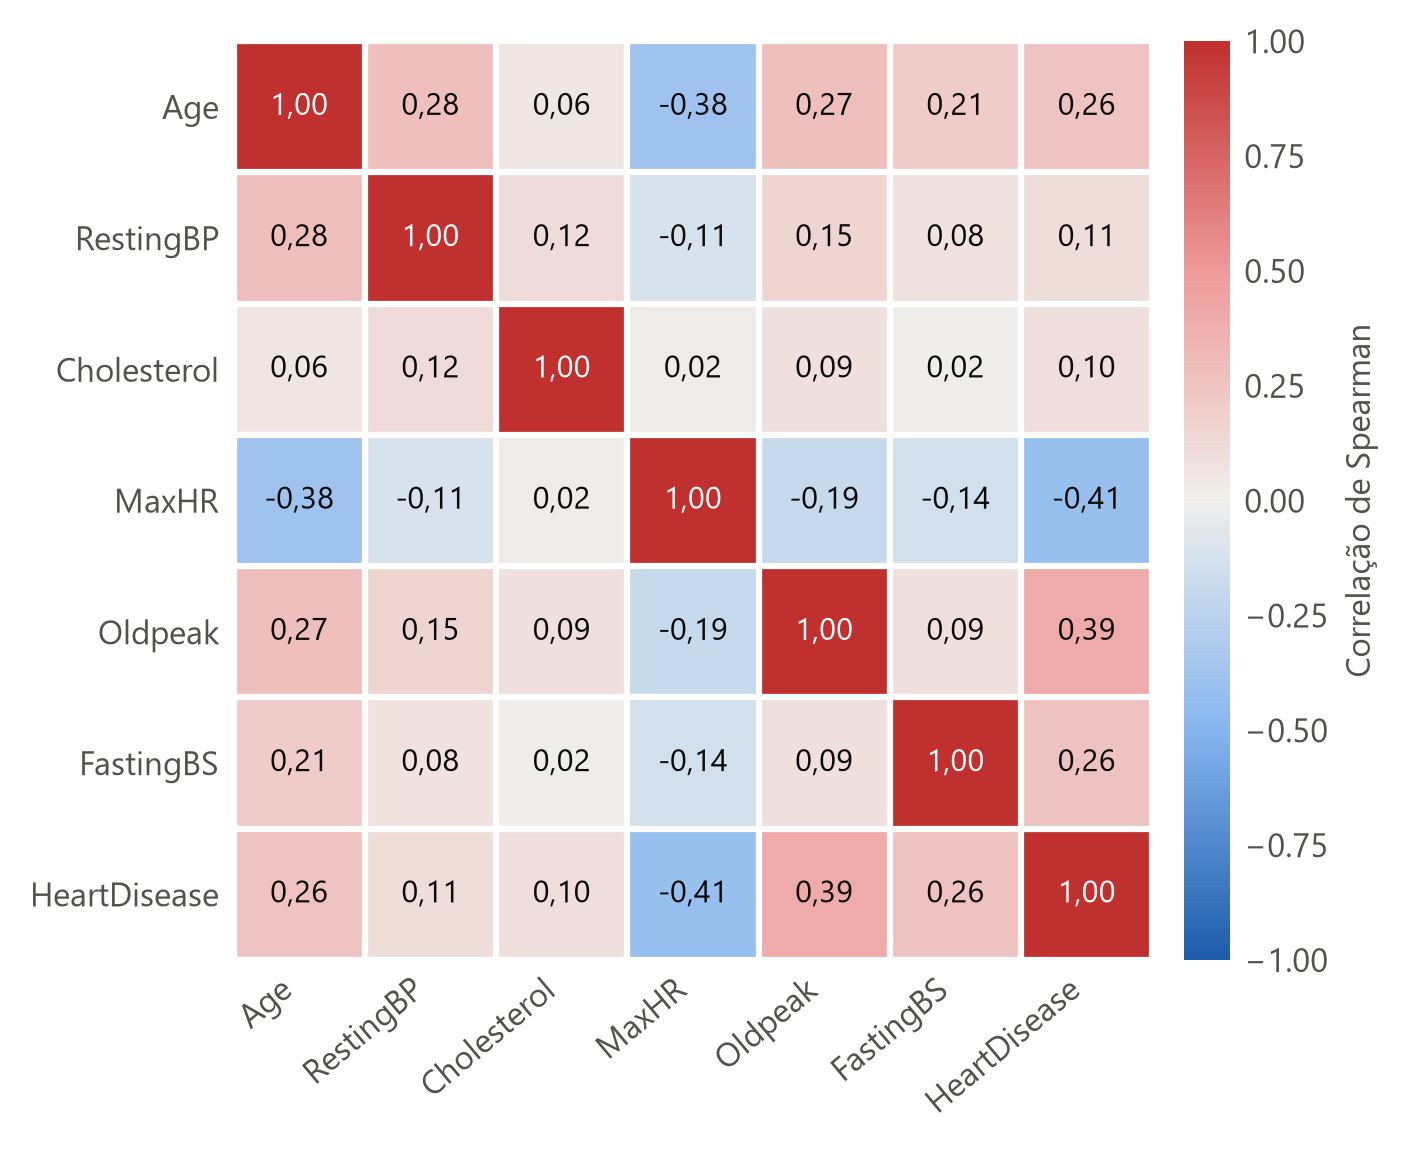

MaxHR         -0.41
Cholesterol    0.10
RestingBP      0.11
Age            0.26
FastingBS      0.26
Oldpeak        0.39
Name: HeartDisease, dtype: float64

In [12]:
corr = eda.fig_correlation(train)
display(Image(str(config.FIGURES_DIR / "fig04_correlacao.png"), width=520))
corr[config.TARGET].drop(config.TARGET).sort_values().round(2)

**Conclusão.** As maiores correlações de Spearman com o alvo são de `MaxHR` (-0,41) e `Oldpeak`
(0,39). Entre atributos, a maior correlação em módulo é 0,38 (`Age` e `MaxHR`): não há redundância
que justifique remover colunas.

## 7. Riscos — algum atributo entrega a resposta? Há viés de amostragem?

- **Vazamento.** Nenhum atributo é derivado do diagnóstico; todos são medidos antes dele (dados
  demográficos, exames de rotina e teste de esforço). Nenhuma correlação com o alvo é alta a ponto
  de levantar suspeita.
- **Viés de coleta.** O padrão de ausência do colesterol indica que a base de origem de cada
  registro (cinco hospitais) está associada ao alvo. O conjunto não traz a coluna de origem, então
  não é possível avaliar o modelo por hospital.
- **Viés de amostragem.** 79% de homens; pacientes encaminhados para investigação cardiológica nos
  anos 1980, nos Estados Unidos e na Europa. A prevalência de 55% não representa a população geral.

## Decisões levadas para a modelagem

| Achado | Decisão |
|---|---|
| Zeros em `Cholesterol` e `RestingBP` | Tratar como ausente; imputar mediana do treino |
| Ausência do colesterol associada ao alvo | Não criar indicador de ausência; medir o efeito à parte |
| Escalas diferentes | Padronizar as numéricas |
| Categóricas nominais | One-hot (binárias em uma coluna) |
| Desbalanceamento leve (55/45) | Estratificar; testar pesos de classe; sem reamostragem |
| Outliers plausíveis | Manter |
| Falso negativo mais grave que falso positivo | AUC-ROC para selecionar; limiar ajustado por F2 |